# 7.1 Персептрон и логические функции / 感知机与逻辑函数
Веса и смещения сначала задаём вручную. Используем NumPy и Matplotlib.
先手动指定权重与偏置，使用 NumPy 和 Matplotlib。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
np.set_printoptions(precision=5, suppress=True)

## Порог и смещение / 阈值与偏置
$z=Xw+b$, $b=-\theta$. Возвращаем 1 только при $z>0$; на границе результат равен 0.
仅当 $z>0$ 时输出 1，边界上输出 0。每一行是一个样本。

In [2]:
X = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])

def step(z):
    return (np.asarray(z) > 0).astype(int)

def perceptron(X, weights, bias):
    return step(X @ np.asarray(weights) + bias)

gates = {"AND": ([0.5, 0.5], -0.7),
         "NAND": ([-0.5, -0.5], 0.7),
         "OR": ([0.5, 0.5], -0.4)}
for name, (weights, bias) in gates.items():
    print(name, perceptron(X, weights, bias))

AND [0 0 0 1]
NAND [1 1 1 0]
OR [0 1 1 1]


## Границы решений / 决策边界
Линия $w_1x_1+w_2x_2+b=0$ разделяет два класса. Цвет показывает результат модели.
直线将平面分成两个类别，背景颜色表示模型输出。

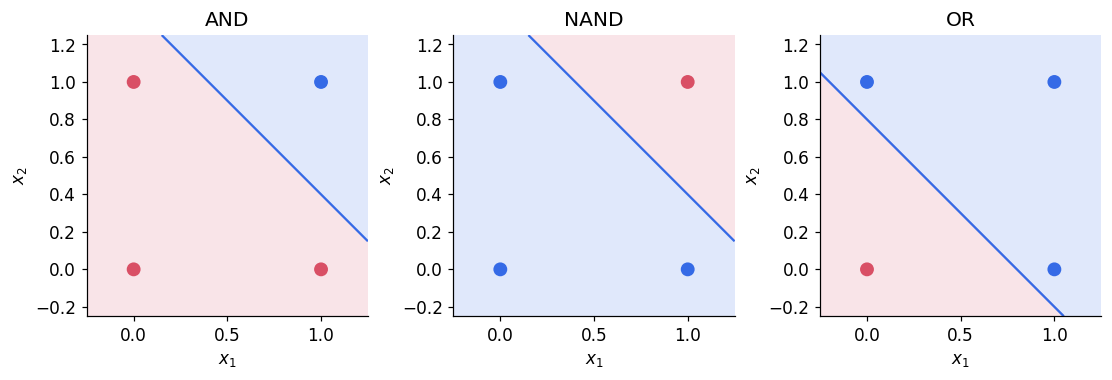

In [3]:
axis = np.linspace(-0.25, 1.25, 180)
gx, gy = np.meshgrid(axis, axis)
points = np.column_stack([gx.ravel(), gy.ravel()])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), layout="constrained")
for ax, (name, (weights, bias)) in zip(axes, gates.items()):
    predicted = perceptron(points, weights, bias).reshape(gx.shape)
    ax.contourf(gx, gy, predicted, levels=[-0.5, 0.5, 1.5],
                colors=[red, blue], alpha=0.15)
    z = (points @ weights + bias).reshape(gx.shape)
    ax.contour(gx, gy, z, levels=[0], colors=[blue])
    target = perceptron(X, weights, bias)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(target == 1, blue, red), s=65)
    ax.set(title=name, xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
plt.show()

## XOR: два слоя / XOR：两层结构
$h_1=\mathrm{NAND}(x_1,x_2)$, $h_2=\mathrm{OR}(x_1,x_2)$, $y=\mathrm{AND}(h_1,h_2)$.
Скрытый слой преобразует исходные признаки. В пространстве $(h_1,h_2)$ классы уже разделяются прямой.
隐藏层变换输入特征；在 $(h_1,h_2)$ 空间中，类别可以用一条直线分开。

In [4]:
h1 = perceptron(X, *gates["NAND"])
h2 = perceptron(X, *gates["OR"])
H = np.column_stack([h1, h2])
y_xor = perceptron(H, *gates["AND"])
print("x1 x2 h1 h2 XOR")
print(np.column_stack([X, H, y_xor]))

x1 x2 h1 h2 XOR
[[0 0 1 0 0]
 [1 0 1 1 1]
 [0 1 1 1 1]
 [1 1 0 1 0]]


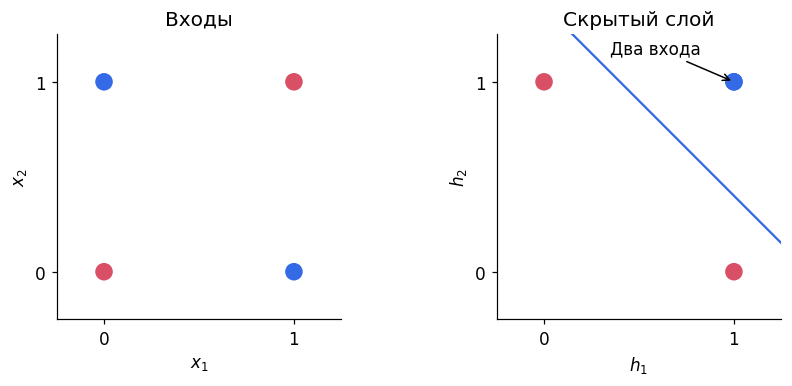

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), layout="constrained")
for ax, data, title in zip(axes, [X, H], ["Входы", "Скрытый слой"]):
    ax.scatter(data[:, 0], data[:, 1], c=np.where(y_xor == 1, blue, red), s=110)
    ax.set(xlim=(-0.25, 1.25), ylim=(-0.25, 1.25), title=title, aspect="equal")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
axes[0].set(xlabel="$x_1$", ylabel="$x_2$")
axes[1].set(xlabel="$h_1$", ylabel="$h_2$")
axes[1].plot([0.15, 1.25], [1.25, 0.15], color=blue)
axes[1].annotate("Два входа", (1, 1), xytext=(0.35, 1.15),
                 arrowprops={"arrowstyle": "->", "color": "black"})
plt.show()

В скрытом пространстве входы $(1,0)$ и $(0,1)$ совпали в точке $(1,1)$. Параметры здесь заданы, а не обучены.
隐藏空间中，输入 $(1,0)$ 与 $(0,1)$ 都映射为 $(1,1)$。这里的参数是手动指定的，尚未训练。